# Week 1: Explore the UCI Online Retail data

This is your **practice notebook**. Work from top to bottom, running **one cell at a time**. The first two code cells set up Python and load the workbook. After that, you write the analysis code.

In VS Code, click a code cell and press **Shift+Enter** to run it. Click a Markdown cell twice to edit your written answers. Save with **⌘S**. If you get stuck, read the hint, try a small change, and look at the result before moving on.

The workbook belongs at `data/raw/Online Retail.xlsx`. If the loading cell cannot find it, download it from the UCI Online Retail dataset page and place it there.

## 1. Import the tools

`pandas` helps us work with tables. `Path` helps find the workbook, even if the notebook is opened from the `notebooks` folder.

In [1]:
import os
from pathlib import Path

# Keep Matplotlib's small settings cache inside this project.
os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".mplconfig"))

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)


## 2. Find and load the workbook

The workbook should be at `data/raw/Online Retail.xlsx`. If the next cell says it cannot find the file, check the spelling and location. The space in `Online Retail.xlsx` is part of the filename.

In [2]:
filename = "Online Retail.xlsx"

# Look in this folder and its parent folders for the project data directory.
starting_folder = Path.cwd().resolve()
project_root = next(
    (folder for folder in [starting_folder, *starting_folder.parents]
     if (folder / "data" / "raw").is_dir()),
    starting_folder,
)
file_path = project_root / "data" / "raw" / filename

if not file_path.exists():
    raise FileNotFoundError(
        f"I couldn't find: {file_path}\n"
        "Download Online Retail.xlsx and place it in the project's data/raw/ folder."
    )

retail = pd.read_excel(file_path, engine="openpyxl")
print(f"Loaded {file_path.name}")
print(f"Rows: {retail.shape[0]:,} | Columns: {retail.shape[1]}")


Loaded Online Retail.xlsx
Rows: 541,909 | Columns: 8


## 3. First example: preview the data

`retail` is the DataFrame loaded above. A DataFrame is a table. Run the example below and look at its column names.

In [3]:
display(retail.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### Exercise 1 — Change the preview

Write code that shows the **first 10 rows**, then shows the **number of rows and columns**. `head(10)` and `shape` are useful here. What does one row appear to represent?

In [9]:
# Your code: show the first 10 rows, then print the table's shape.
display(retail.head(10))
print(retail.shape) 


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


(541909, 8)


**My observation:** 
Each row represents a purchase.

## 4. Explore the columns

`retail.info()` reports column types and nonmissing counts. `retail.columns` gives the column names. Run both, then decide which fields are IDs, numbers, dates, and descriptions.

In [19]:
# Your code: inspect the column types and display the column names.
display(retail.info())
print(retail.columns)


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


None

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')


**My observation:** Which column identifies an invoice? Which identifies a product? Which two columns might later help calculate sales?

## 5. Find missing values

A missing value is an empty entry. `retail.isna()` marks missing entries as `True`. You can use `.sum()` to count them by column. Write code that counts missing values in **every column**. Then find the column with the largest count.

In [60]:
# Your code: count missing values by column.
display(retail.isna().sum())


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

**My observation:** Which column has the most missing values? If a customer ID is missing, can that row still help answer a question about total sales? Explain your reasoning.

## 6. Look for unusual quantities and prices

A comparison such as `retail["Quantity"] < 0` produces `True` or `False` for each row. Counting the `True` values tells you how often it happens.

Write code to count rows with a **negative Quantity** and rows with a **zero UnitPrice**. Also find the **maximum Quantity**. Do not delete any rows yet.

In [65]:
# Your code: count negative quantities and zero prices; find the largest quantity.
negative_count = (retail["Quantity"] < 0).sum()
zero_price_count = (retail["UnitPrice"] == 0).sum()

max_quantity = retail["Quantity"].max()

print(negative_count)
print(zero_price_count)
print(max_quantity)



10624
2515
80995


**My observation:** What could a negative quantity mean? What would you investigate before calling it a bad record?

## 7. Rows are not the same as orders

One invoice can contain multiple products. Compare the number of rows with the number of unique invoice numbers. The method `.nunique()` counts distinct values in a column.

In [37]:
# Your code: print the row count and the number of unique InvoiceNo values.
print(retail.nunique())
print(retail.shape)


InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64
(541909, 8)


**My explanation:** Why are there more rows than invoices? Why would counting rows overstate the number of orders? There are more rows than invoices becauses one single invoice can contain multiple purchases.

## 8. Practice filtering

Find purchases with `Country` equal to `"Germany"`. Start with `retail["Country"] == "Germany"`: that is a mask of `True` and `False` values. Put the mask inside `retail[...]` to select matching rows. Show a few rows and count how many matched.

In [ ]:
# Your code: create a Germany-only DataFrame, preview it, and count its rows.
germany_only = retail[retail["Country"] == "Germany"]

display(germany_only.head())


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
1109,536527,22809,SET OF 6 T-LIGHTS SANTA,6,2010-12-01 13:04:00,2.95,12662.0,Germany
1110,536527,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,6,2010-12-01 13:04:00,2.55,12662.0,Germany
1111,536527,84945,MULTI COLOUR SILVER T-LIGHT HOLDER,12,2010-12-01 13:04:00,0.85,12662.0,Germany
1112,536527,22242,5 HOOK HANGER MAGIC TOADSTOOL,12,2010-12-01 13:04:00,1.65,12662.0,Germany
1113,536527,22244,3 HOOK HANGER MAGIC GARDEN,12,2010-12-01 13:04:00,1.95,12662.0,Germany


9495

## 9. Optional chart challenge

Try a histogram of `Quantity` using `.plot(kind="hist", bins=40)`. A histogram groups values into ranges. If one very large value makes the chart hard to read, describe that limitation; do not remove data without explaining why.

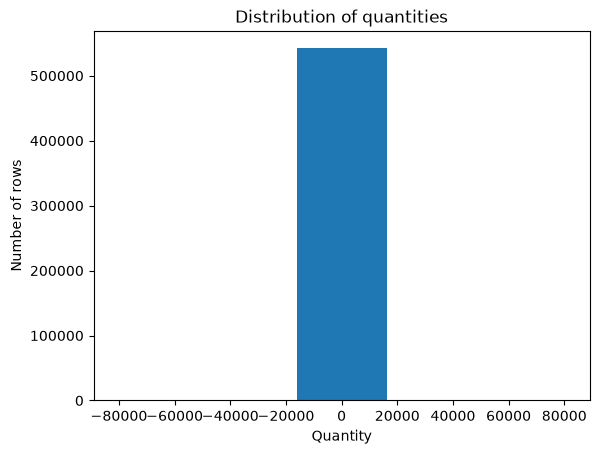

In [58]:
# Optional: make a Quantity histogram and label its axes.
retail["Quantity"].plot(kind="hist", bins=5)

plt.xlabel("Quantity")
plt.ylabel("Number of rows")
plt.title("Distribution of quantities")
plt.show()



## 10. Your Week 1 findings

Edit this cell after completing the exercises. Write **at least five observations in your own words**. Include evidence from your results, plus one question you would investigate before calculating revenue.

1. **Rows and columns:** There are 500,000+ rows and 8 columns.
2. **Missing values:** Some rows have missing descriptions and/or customer IDs.
3. **Quantities or prices:** There are some invoices with negative invoices, I am not sure what they could mean, perhaps a refund?
4. **Rows versus invoices:** There seems to be more rows than there are invoices because a single invoice can contain multiple purchased products.
5. **Something else I noticed:** The Histogram seems to be accurate but it's hard to see the data because the unit sizes are large.

**Question to investigate before calculating revenue:**
I need to investigate how many cancellations, zero prices, and refunds there cumulatively are before calculating the revenue.
**What I learned about Pandas:**
isNa() shows me how many empty values there are in each of a dataframe's columns.

When you can explain these findings, you are ready for Week 2: cleaning the data.